In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(seed = 2405)

# Question 1 - Asian Option Price Estimate 

Asian Option Payoff = $(K - \bar{S})_+,$ where $\bar{S} = \frac{1}{m} \sum_{i=1}^m{S_{t_i}} $

Num simulated steps = m +1 (t=0 case)
dt = T/m = 0.5/50 = 0.01 


In [55]:
## Set parameters (annualized)
S0 = 100 
K = 95
r = 0.03
q = 0.02 
sigma = 0.35
T = 0.5 
m = 50 

# User defined ---- paths for simulation
n_paths = 1000


In [57]:
def price_asian_put(n_paths, m, r, q, sigma, T, K):
    """
    1. Create grid of random variables (num_paths x time steps)
    2. Compute drift and diffucison term and add -> log returns 
    3. Cummulative sum across the time steps per path, exponentiate tha mulitply by intiial price S0 -> price evolution per path 
    4. Find average price per path and calculate payoff 
    5. Find option price by discoutning the average payof across simulated paths 
    """
    dt = T/m

    Z = rng.standard_normal((n_paths, m))

    drift = (r-q - 0.5 *sigma**2) * dt
    diffusion = sigma * np.sqrt(dt) * Z

    log_returns  = drift + diffusion 
    log_paths = np.cumsum(log_returns, axis = 1)
    paths = S0 * np.exp(log_paths)

    avg_prices = np.mean(paths, axis = 1)
    payoffs = np.maximum(K - avg_prices, 0)

    price = np.exp(-r * T) * payoffs.mean()
    
    # For plotting purposes
    t_0 = np.full((n_paths, 1), S0)
    plot_paths = np.concatenate([t_0 ,paths], axis =1)

    return price, plot_paths

In [53]:
def plot_mc_simulation(plot_paths:np.ndarray, num_path: int = 10):
    sns.set_theme(style="ticks", context="paper", font_scale=1.25)
    colors = sns.color_palette("deep")

    # For more info on the colours "https://seaborn.pydata.org/tutorial/color_palettes.html" 

    time = np.linspace(0,T, paths.shape[1])

    fig, ax = plt.subplots(figsize=(9, 5), dpi=150)

    # Only choose 10 paths and mainly plot the 10th and 90th percentile alognside the median
    p10, p50, p90 = np.percentile(paths, [10, 50, 90], axis=0)

    for path in paths[:10]:
        ax.plot(time,path, color = 'gray', alpha = 0.4, linewidth = 0.6)

    ax.plot(time, p10, label = '10th percentile', color = colors[3], linewidth = 2)
    ax.plot(time, p50, label = '50th percentile - Median', color = colors[2], linewidth = 2)
    ax.plot(time, p90, label = '90th percentile', color = colors[0], linewidth = 2)

    ax.fill_between(time, p10, p90, color=colors[0], alpha=0.04)

    ax.set(
        xlabel="Time (years)",
        ylabel="Stock price ($)",
        title=f"Monte Carlo Simulation of Stock Price Paths - {num_path} paths"
    )

    ax.set_xlim(0, T)
    ax.margins(x=0)
    ax.legend()
    sns.despine()
    plt.tight_layout()
    plt.show()

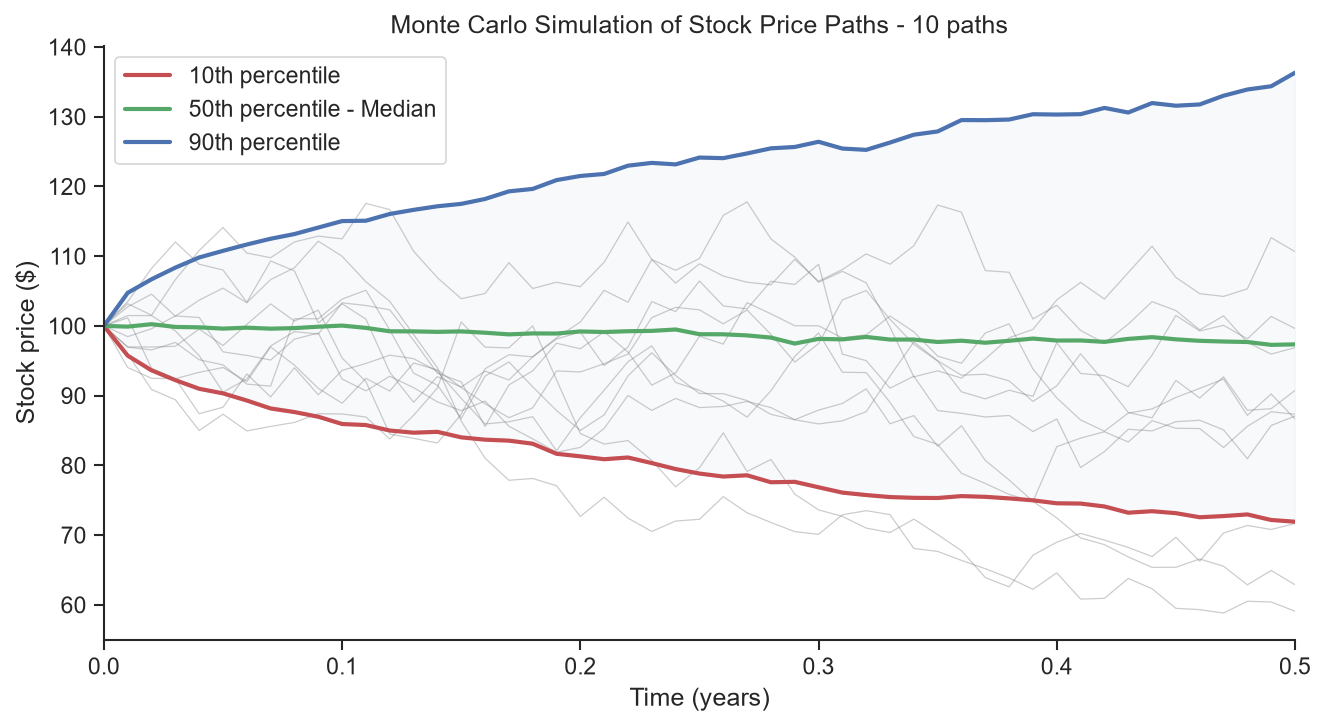

In [54]:
price, paths = price_asian_put(1000, m,r,q,sigma,T,K)
plot_mc_simulation(paths, 10)